# Oddball Response — Behavioral Measures

Violin plots for RT, Coefficient of Variation RT, d-prime, and Errors.
Stats are in R (analysis_behavior_oddball_flow.qmd / analysis_behavior_oddball_load.qmd).

**Toggles:** `PAPER`, `NOVEL`


In [20]:
from datetime import datetime
from pathlib import Path
from matplotlib.gridspec import GridSpec
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def find_repo_root(marker="core") -> Path:
    """Walk up from the current directory until a folder containing
    `marker` (e.g. core/) is found -- avoids hardcoding folder depth,
    which breaks every time notebooks get moved."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise RuntimeError(f"Could not locate repo root (no '{marker}/' found above {Path.cwd()})")

sys.path.insert(0, str(find_repo_root() / 'core'))
from participants import get_participants

sns.set_theme()
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
})

# ==============================================================================
# CONFIGURATION
# ==============================================================================

PAPER    = "flow"   # "flow" | "load"
PARADIGM = "active" # "active" only (passive has no oddball response)
NOVEL    = True     # True = d_withnovels | False = d_nonovels

DATE_STR    = datetime.today().strftime("%Y%m%d")
DATE_SOURCE = "20261016"  # update to match your compute_measures CSV date
STUDY       = "Active"

if sys.platform == "win32":
    root_data = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/measures/behavior")
    root_img  = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/{PAPER}/behavior")
else:
    root_data = Path(f"/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/easures/behavior")
    root_img  = Path(f"/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/{PAPER}/behavior")

root_img.mkdir(parents=True, exist_ok=True)

DPRIME_COL = "d_withnovels" if NOVEL else "d_nonovels"
NOVEL_STR  = "withnovels"   if NOVEL else "nonovels"

print(f"Paper: {PAPER.upper()} | Novel: {NOVEL} | d' col: {DPRIME_COL}")


Paper: FLOW | Novel: True | d' col: d_withnovels


In [21]:
# ==============================================================================
# Load data and filter to included participants
# ==============================================================================

included = list(get_participants(PAPER, PARADIGM).keys())
n        = len(included)

def load_and_filter(fname):
    df = pd.read_csv(root_data / fname)
    return df[df["participant"].isin(included)].copy()

df_rt     = load_and_filter(f"{DATE_SOURCE}_active_oddball_rt_{PAPER}.csv")
df_dprime = load_and_filter(f"{DATE_SOURCE}_active_oddball_dprime_{PAPER}.csv")
df_errors = load_and_filter(f"{DATE_SOURCE}_active_oddball_errors_{PAPER}.csv")

print(f"N included: {n} participants")
print(f"RT conditions    : {sorted(df_rt['condition'].unique())}")
print(f"D-prime conditions: {sorted(df_dprime['condition'].unique())}")


N included: 36 participants
RT conditions    : ['AudioOnly1', 'AudioOnly2', 'High Flow', 'Low Flow']
D-prime conditions: ['AudioOnly1', 'AudioOnly2', 'High Flow', 'Low Flow']


In [22]:
# ==============================================================================
# Condition config
# ==============================================================================

if PAPER == "flow":
    CONDITIONS = ["High Flow", "Low Flow"]
    COLORS     = {"High Flow": "#E74C3C", "Low Flow": "#2ECC71"}
    # Expected directions for paired lines
    # red = unexpected / gray = expected
    EXPECTED = {
        "rt_mean":  "higher",  # expect High Flow RT > Low Flow RT (slower)
        "rt_cv":    "higher",  # expect High Flow CV > Low Flow CV
        DPRIME_COL: "lower",   # expect High Flow d' < Low Flow d'
        "n_errors": "higher",  # expect High Flow errors > Low Flow errors
    }
else:  # load
    CONDITIONS = ["Simple", "Complex"]
    COLORS     = {"Simple": "#3498DB", "Complex": "#F39C12"}
    EXPECTED = {
        "rt_mean":  "lower",   # expect Simple RT < Complex RT
        "rt_cv":    "lower",
        DPRIME_COL: "higher",  # expect Simple d' > Complex d'
        "n_errors": "lower",
    }

# Filter to conditions of interest
df_rt     = df_rt[df_rt["condition"].isin(CONDITIONS)]
df_dprime = df_dprime[df_dprime["condition"].isin(CONDITIONS)]
df_errors = df_errors[df_errors["condition"].isin(CONDITIONS)]

print(f"Conditions: {CONDITIONS}")


Conditions: ['High Flow', 'Low Flow']


In [23]:
# ==============================================================================
# Helper: violin + paired lines
# ==============================================================================

# COLOR_CONFIRMS = "#2196F3"   # blue  — as expected
# COLOR_VIOLATES = "#FF9800"   # amber — unexpected
# COLOR_EQUAL    = "#BDBDBD"   # gray


COLOR_CONFIRMS = "#9E9E9E"   # lighter gray — as expected
COLOR_VIOLATES = "#F0A500"   # bright golden amber — opposite direction
COLOR_EQUAL    = COLOR_CONFIRMS

def violin_paired(ax, data, participant_col, value_col, conditions, colors,
                  expected_dir=None, ylabel="", title=""):
    
    data = data.copy()
    data["condition"] = pd.Categorical(data["condition"],
                                        categories=conditions, ordered=True)
    sns.violinplot(
        data=data, x="condition", y=value_col,
        palette=colors, order=conditions,
        cut=0, inner="quart", ax=ax,
    )

    count_confirms = count_violates = count_equal = 0

    for p in data[participant_col].unique():
        pdata = data[(data[participant_col] == p) &
                     (data["condition"].isin(conditions))]
        if len(pdata) == 2:
            scores = pdata.set_index("condition").loc[conditions, value_col].values
            v1, v2 = scores[0], scores[1]

            if expected_dir is None:
                color = "#888888"
            elif v1 == v2:
                color = COLOR_EQUAL;    count_equal    += 1
            elif (expected_dir == "lower"  and v1 < v2) or                  (expected_dir == "higher" and v1 > v2):
                color = COLOR_CONFIRMS; count_confirms += 1
            else:
                color = COLOR_VIOLATES; count_violates += 1

            ax.plot([0, 1], scores, marker='o', linestyle='-',
                    color=color, alpha=0.5, linewidth=1.1)

    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticklabels(conditions, fontweight='bold')

    return count_confirms, count_violates, count_equal

print("Helper ready.")


Helper ready.


Reaction Time: confirms=17, violates=19, equal=0
CV of RT: confirms=20, violates=16, equal=0
d' (withnovels): confirms=16, violates=20, equal=0
Errors: confirms=16, violates=18, equal=2


C:\Users\anguyen\AppData\Local\Temp\ipykernel_14544\2544912506.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



Saved -> 20261016_active_flow_oddball_response_withnovels


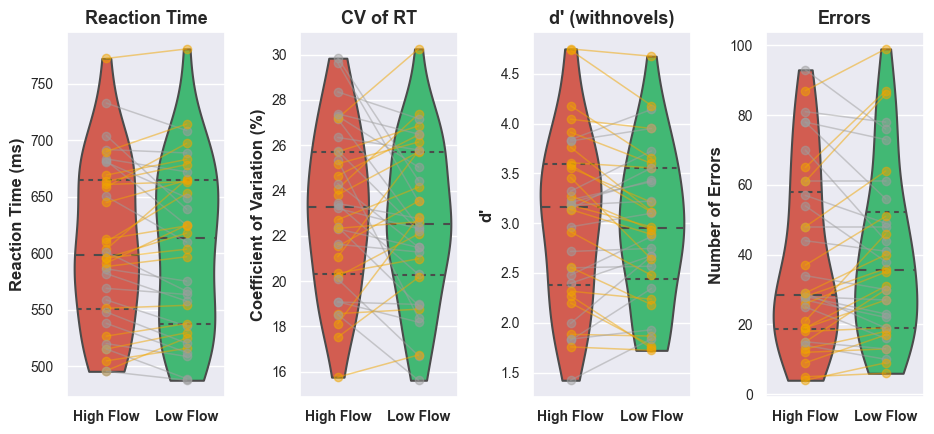

In [24]:
# ==============================================================================
# Main figure — 4 panels
# ==============================================================================

MEASURES = [
    {"df": df_rt,     "col": "rt_mean",   "ylabel": "Reaction Time (ms)",          "title": "Reaction Time"},
    {"df": df_rt,     "col": "rt_cv",     "ylabel": "Coefficient of Variation (%)", "title": "CV of RT"},
    {"df": df_dprime, "col": DPRIME_COL,  "ylabel": "d'",                           "title": f"d' ({NOVEL_STR})"},
    {"df": df_errors,
     "col":    "n_errors"   if PAPER == "flow" else "pct_errors",
     "ylabel": "Number of Errors" if PAPER == "flow" else "Errors (%)",
     "title":  "Errors"},
    ]

fig = plt.figure(constrained_layout=True, figsize=(9.5, 4.5))
spec = GridSpec(nrows=1, ncols=4, figure=fig)

for idx, m in enumerate(MEASURES):
    ax = fig.add_subplot(spec[idx])
    c, v, e = violin_paired(
        ax,
        data            = m["df"],
        participant_col = "participant",
        value_col       = m["col"],
        conditions      = CONDITIONS,
        colors          = COLORS,
        expected_dir    = EXPECTED.get(m["col"]),
        ylabel          = m["ylabel"],
        title           = m["title"],
    )
    print(f"{m['title']}: confirms={c}, violates={v}, equal={e}")

plt.tight_layout()
fname = root_img / f"{DATE_STR}_{PARADIGM}_{PAPER}_oddball_response_{NOVEL_STR}"
plt.savefig(f"{fname}.svg", dpi=600, bbox_inches="tight")
plt.savefig(f"{fname}.pdf", dpi=600, bbox_inches="tight")

print(f"\nSaved -> {fname.name}")
plt.show()
